# **PREPROCESSING**

In [ ]:
!pip install pandas nltk Sastrawi
!pip install pyspellchecker

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

import re
import string
import pandas as pd
from spellchecker import SpellChecker
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 71.3 MB/s eta 0:00:00


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_excel("/content/drive/MyDrive/SKRIPSI/DATA/Dataset_Final_Gabungan.xlsx")
df.to_csv("/content/drive/MyDrive/SKRIPSI/DATA/Dataset_Final_Gabungan.csv", index=False, encoding="utf-8")
df = pd.read_csv("/content/drive/MyDrive/SKRIPSI/DATA/Dataset_Final_Gabungan.csv")
df

,created_at,username,full_text
0,2026-07-03T05:52:48.000Z,zgemey,the real teriak
1,2026-07-03T06:54:49.000Z,sleeppyy374,deniall abisss komennya 😭
2,2026-07-03T08:44:15.000Z,matchaoaas,[Sticker] gua gabisa bayangin kalo AHYEON yang...
3,2026-07-03T09:06:18.000Z,naevat3rs,[Sticker] anti kritik bgt
4,2026-07-03T09:32:19.000Z,blueberrygirl324,"[Sticker] ""mungkin jadwal nya lagi padat jadi ..."
...,...,...,...
17427,NaN,tanzissy,gue jadi fans mereka ga terima idolnya dibawa ...
17428,NaN,brownnnin,Setuju banget klo mau kritik ya boleh aja ini ...
17429,NaN,ArifiantoR5,sekarang balik tanya aja sama mereka.. fave ka...
17430,NaN,ryzaoryza,"Giliran kali ini diajak buat dukung lagi, nara..."


In [ ]:
# FILTERING

# Menghapus data duplikat
df = df.drop_duplicates(subset=["full_text"])

# Menghapus data kosong
df = df.dropna(subset=["full_text"])
df

,created_at,username,full_text
0,2026-07-03T05:52:48.000Z,zgemey,the real teriak
1,2026-07-03T06:54:49.000Z,sleeppyy374,deniall abisss komennya 😭
2,2026-07-03T08:44:15.000Z,matchaoaas,[Sticker] gua gabisa bayangin kalo AHYEON yang...
3,2026-07-03T09:06:18.000Z,naevat3rs,[Sticker] anti kritik bgt
4,2026-07-03T09:32:19.000Z,blueberrygirl324,"[Sticker] ""mungkin jadwal nya lagi padat jadi ..."
...,...,...,...
17427,NaN,tanzissy,gue jadi fans mereka ga terima idolnya dibawa ...
17428,NaN,brownnnin,Setuju banget klo mau kritik ya boleh aja ini ...
17429,NaN,ArifiantoR5,sekarang balik tanya aja sama mereka.. fave ka...
17430,NaN,ryzaoryza,"Giliran kali ini diajak buat dukung lagi, nara..."


In [ ]:
# CLEANING TEXT

def clean_text(text):
    if not isinstance(text,str):
        return ""
    # URL
    text = re.sub(r'http\S+|www\S+','',text)
    # Mention
    text = re.sub(r'@\w+','',text)
    # Hapus simbol hashtag saja
    text = re.sub(r'#','',text)
    # Emoji
    emoji_pattern = re.compile("["
            u"\U0001F600-\U0001F64F"
            u"\U0001F300-\U0001F5FF"
            u"\U0001F680-\U0001F6FF"
            u"\U0001F700-\U0001F77F"
            u"\U0001F780-\U0001F7FF"
            u"\U0001F800-\U0001F8FF"
            u"\U0001F900-\U0001F9FF"
            u"\U0001FA00-\U0001FA6F"
            u"\U0001FA70-\U0001FAFF"
            u"\U0001F1E0-\U0001F1FF"
            "]+",flags=re.UNICODE)
    text = emoji_pattern.sub("",text)
    # Emoticon
    text = re.sub(r'(?::|;|=)(?:-)?(?:\)|\(|D|P)','',text)
    # Angka
    text = re.sub(r'\d+','',text)
    # Tanda baca
    text = text.translate(str.maketrans("","",string.punctuation))
    # Karakter selain huruf
    text = re.sub(r'[^a-zA-Z\s]',' ',text)
    # Spasi berlebih
    text = re.sub(r'\s+',' ',text).strip()
    return text

df["clean_text"] = df["full_text"].astype(str).apply(clean_text)
df[["full_text","clean_text"]].head()

,full_text,clean_text
0,the real teriak,the real teriak
1,deniall abisss komennya 😭,deniall abisss komennya
2,[Sticker] gua gabisa bayangin kalo AHYEON yang...,Sticker gua gabisa bayangin kalo AHYEON yang d...
3,[Sticker] anti kritik bgt,Sticker anti kritik bgt
4,"[Sticker] ""mungkin jadwal nya lagi padat jadi ...",Sticker mungkin jadwal nya lagi padat jadi ga ...


In [ ]:
# CASE FOLDING

def case_folding(text):
    return text.lower()

df["case_folding"] = df["clean_text"].apply(case_folding)
df[["clean_text","case_folding"]].head()

,clean_text,case_folding
0,the real teriak,the real teriak
1,deniall abisss komennya,deniall abisss komennya
2,Sticker gua gabisa bayangin kalo AHYEON yang d...,sticker gua gabisa bayangin kalo ahyeon yang d...
3,Sticker anti kritik bgt,sticker anti kritik bgt
4,Sticker mungkin jadwal nya lagi padat jadi ga ...,sticker mungkin jadwal nya lagi padat jadi ga ...


In [ ]:
# SLANGWORD NORMALIZATION

import json
slang_path="/content/drive/MyDrive/SKRIPSI/_json_colloquial-indonesian-lexicon.json"

with open(slang_path,"r",encoding="utf-8") as f:
    slang_dict=json.load(f)

slang_dict={k.lower():v.lower() for k,v in slang_dict.items()}
print("Jumlah slang:",len(slang_dict))

def normalize_slang(text):
    if not isinstance(text,str):
        return ""

    words=text.split()
    normalized=[
        slang_dict.get(word,word)
        for word in words
    ]
    return " ".join(normalized)

df["slang_normalization"]=df["case_folding"].apply(normalize_slang)
df[["case_folding","slang_normalization"]].head()

Jumlah slang: 4388


,case_folding,slang_normalization
0,the real teriak,the real teriak
1,deniall abisss komennya,deniall habis komennya
2,sticker gua gabisa bayangin kalo ahyeon yang d...,sticker gue enggak bisa bayangkan kalo ahyeon ...
3,sticker anti kritik bgt,sticker anti kritik banget
4,sticker mungkin jadwal nya lagi padat jadi ga ...,sticker mungkin jadwal nya lagi padat jadi tid...


In [ ]:
# STOPWORD REMOVAL (tanpa tahapan spell check)

from nltk.corpus import stopwords
stop_words=set(stopwords.words("indonesian"))

def remove_stopwords(text):
    if not isinstance(text,str):
        return ""
    words=text.split()
    filtered=[
        word
        for word in words
        if word not in stop_words
    ]
    return " ".join(filtered)

df["stopword_removed2"]=df["slang_normalization"].apply(remove_stopwords)
df[["slang_normalization","stopword_removed2"]].head()

,slang_normalization,stopword_removed2
0,the real teriak,the real teriak
1,deniall habis komennya,deniall habis komennya
2,sticker gue enggak bisa bayangkan kalo ahyeon ...,sticker gue bayangkan kalo ahyeon posisi dihuj...
3,sticker anti kritik banget,sticker anti kritik banget
4,sticker mungkin jadwal nya lagi padat jadi tid...,sticker jadwal nya padat stabil capek grogi


In [ ]:
# STEMMING (tanpa tahapan spell check)

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory=StemmerFactory()
stemmer=factory.create_stemmer()

def stemming(text):
    return stemmer.stem(text)

df["stemmed2"]=df["stopword_removed2"].apply(stemming)
df[["stopword_removed2","stemmed2"]].head()

,stopword_removed2,stemmed2
0,the real teriak,the real teriak
1,deniall habis komennya,deniall habis komennya
2,sticker gue bayangkan kalo ahyeon posisi dihuj...,sticker gue bayang kalo ahyeon posisi hujat ha...
3,sticker anti kritik banget,sticker anti kritik banget
4,sticker jadwal nya padat stabil capek grogi,sticker jadwal nya padat stabil capek grogi


In [ ]:
# TOKENIZATION (tanpa tahapan spell check)

def tokenize(text):
    if not isinstance(text, str):
        return []
    return word_tokenize(text)

df["token"]=df["stemmed2"].apply(tokenize)
df[["stemmed2","token"]].head()

,stemmed2,token
0,the real teriak,"[the, real, teriak]"
1,deniall habis komennya,"[deniall, habis, komennya]"
2,sticker gue bayang kalo ahyeon posisi hujat ha...,"[sticker, gue, bayang, kalo, ahyeon, posisi, h..."
3,sticker anti kritik banget,"[sticker, anti, kritik, banget]"
4,sticker jadwal nya padat stabil capek grogi,"[sticker, jadwal, nya, padat, stabil, capek, g..."


In [ ]:
df_final = df[[
    "created_at",
    "username",
    "clean_text",
    "case_folding",
    "slang_normalization",
    "stopword_removed2",
    "stemmed2",
    "token"
]].copy()
df_final

,created_at,username,clean_text,case_folding,slang_normalization,stopword_removed2,stemmed2,token
0,2026-07-03T05:52:48.000Z,zgemey,the real teriak,the real teriak,the real teriak,the real teriak,the real teriak,"[the, real, teriak]"
1,2026-07-03T06:54:49.000Z,sleeppyy374,deniall abisss komennya,deniall abisss komennya,deniall habis komennya,deniall habis komennya,deniall habis komennya,"[deniall, habis, komennya]"
2,2026-07-03T08:44:15.000Z,matchaoaas,Sticker gua gabisa bayangin kalo AHYEON yang d...,sticker gua gabisa bayangin kalo ahyeon yang d...,sticker gue enggak bisa bayangkan kalo ahyeon ...,sticker gue bayangkan kalo ahyeon posisi dihuj...,sticker gue bayang kalo ahyeon posisi hujat ha...,"[sticker, gue, bayang, kalo, ahyeon, posisi, h..."
3,2026-07-03T09:06:18.000Z,naevat3rs,Sticker anti kritik bgt,sticker anti kritik bgt,sticker anti kritik banget,sticker anti kritik banget,sticker anti kritik banget,"[sticker, anti, kritik, banget]"
4,2026-07-03T09:32:19.000Z,blueberrygirl324,Sticker mungkin jadwal nya lagi padat jadi ga ...,sticker mungkin jadwal nya lagi padat jadi ga ...,sticker mungkin jadwal nya lagi padat jadi tid...,sticker jadwal nya padat stabil capek grogi,sticker jadwal nya padat stabil capek grogi,"[sticker, jadwal, nya, padat, stabil, capek, g..."
...,...,...,...,...,...,...,...,...
17427,NaN,tanzissy,gue jadi fans mereka ga terima idolnya dibawa ...,gue jadi fans mereka ga terima idolnya dibawa ...,gue jadi fan mereka tidak terima idolnya dibaw...,gue fan terima idolnya dibawa bawa benci idol ...,gue fan terima idolnya bawa bawa benci idol do...,"[gue, fan, terima, idolnya, bawa, bawa, benci,..."
17428,NaN,brownnnin,Setuju banget klo mau kritik ya boleh aja ini ...,setuju banget klo mau kritik ya boleh aja ini ...,setuju banget kalo mau kritik ya boleh saja in...,setuju banget kalo kritik ya menghujat sebegit...,tuju banget kalo kritik ya hujat begitu gue fa...,"[tuju, banget, kalo, kritik, ya, hujat, begitu..."
17429,NaN,ArifiantoR5,sekarang balik tanya aja sama mereka fave kali...,sekarang balik tanya aja sama mereka fave kali...,sekarang balik tanya saja sama mereka fave kal...,fave berteman kim dita zayyan dukung notice ka...,fave teman kim dita zayyan dukung notice kagak...,"[fave, teman, kim, dita, zayyan, dukung, notic..."
17430,NaN,ryzaoryza,Giliran kali ini diajak buat dukung lagi naras...,giliran kali ini diajak buat dukung lagi naras...,giliran kali ini diajak buat dukung lagi naras...,giliran kali diajak dukung narasinya bilang ad...,gilir kali ajak dukung narasi bilang adil lu p...,"[gilir, kali, ajak, dukung, narasi, bilang, ad..."


In [ ]:
df_final["stemmed2"].isna().sum()

np.int64(0)

In [ ]:
# Menampilkan data yang bertipe float pada kolom stemmed2
float_data = df_final[df_final["stemmed2"].apply(lambda x: isinstance(x, float))]
print("Jumlah data float:", len(float_data))
float_data

Jumlah data float: 0


,created_at,username,clean_text,case_folding,slang_normalization,stopword_removed2,stemmed2,token


In [ ]:
df_final = df_final.dropna(subset=["stemmed2"]).reset_index(drop=True)
print("Jumlah data setelah menghapus NaN :", len(df_final))
print(df_final["stemmed2"].isna().sum())

Jumlah data setelah menghapus NaN : 17429
0


In [ ]:
df_final.to_csv(
    "/content/drive/MyDrive/SKRIPSI/T_PT8/data_prepros8.csv",
    index=False
)

# **INSET LEXICON**

https://www.researchgate.net/publication/321757985_InSet_Lexicon_Evaluation_of_a_Word_List_for_Indonesian_Sentiment_Analysis_in_Microblogs

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [ ]:
positive_path = "/content/drive/MyDrive/SKRIPSI/InSet-master/InSet-master/positive.tsv"
negative_path = "/content/drive/MyDrive/SKRIPSI/InSet-master/InSet-master/negative.tsv"

In [ ]:
positive_df = pd.read_csv(
    positive_path,
    sep="\t"
)

negative_df = pd.read_csv(
    negative_path,
    sep="\t"
)
positive_df.head()

,word,weight
0,hai,3
1,merekam,2
2,ekstensif,3
3,paripurna,1
4,detail,2


In [ ]:
positive_df["weight"] = positive_df["weight"].astype(int)
negative_df["weight"] = negative_df["weight"].astype(int)

In [ ]:
positive_dict = dict(
    zip(
        positive_df["word"],
        positive_df["weight"]
    )
)

negative_dict = dict(
    zip(
        negative_df["word"],
        negative_df["weight"]
    )
)

In [ ]:
def sentiment_score(tokens):
    if not isinstance(tokens, list):
        return 0

    score = 0
    for word in tokens:
        if word in positive_dict:
            score += positive_dict[word]
        elif word in negative_dict:
            score += negative_dict[word]
    return score

In [ ]:
df_final["sentiment_score"] = df_final["token"].apply(sentiment_score)
df_final[["token","sentiment_score"]].head(10)

,token,sentiment_score
0,"[the, real, teriak]",0
1,"[deniall, habis, komennya]",3
2,"[sticker, gue, bayang, kalo, ahyeon, posisi, h...",0
3,"[sticker, anti, kritik, banget]",-6
4,"[sticker, jadwal, nya, padat, stabil, capek, g...",3
5,"[suara, carmen, bagus, carmen, semangat, carme...",13
6,"[anti, kritik, banget, kalo, ngritik, oeang, g...",-5
7,"[sticker, jujur, gaenak]",1
8,"[group, hybe, baemon, gapapa, aman, lupa, baem...",-1
9,"[gue, hatcu, denial, suara, carmen]",2


In [ ]:
def sentiment_label(score):
    if score > 0:
        return "Positif"
    elif score < 0:
        return "Negatif"
    else:
        return "Netral"

df_final["sentiment"] = df_final["sentiment_score"].apply(sentiment_label)
df_final[[
"token",
"sentiment_score",
"sentiment"
]].head(10)

,token,sentiment_score,sentiment
0,"[the, real, teriak]",0,Netral
1,"[deniall, habis, komennya]",3,Positif
2,"[sticker, gue, bayang, kalo, ahyeon, posisi, h...",0,Netral
3,"[sticker, anti, kritik, banget]",-6,Negatif
4,"[sticker, jadwal, nya, padat, stabil, capek, g...",3,Positif
5,"[suara, carmen, bagus, carmen, semangat, carme...",13,Positif
6,"[anti, kritik, banget, kalo, ngritik, oeang, g...",-5,Negatif
7,"[sticker, jujur, gaenak]",1,Positif
8,"[group, hybe, baemon, gapapa, aman, lupa, baem...",-1,Negatif
9,"[gue, hatcu, denial, suara, carmen]",2,Positif


In [ ]:
df_final["sentiment"].value_counts()

,count
sentiment,
Positif,8336
Negatif,5704
Netral,3389


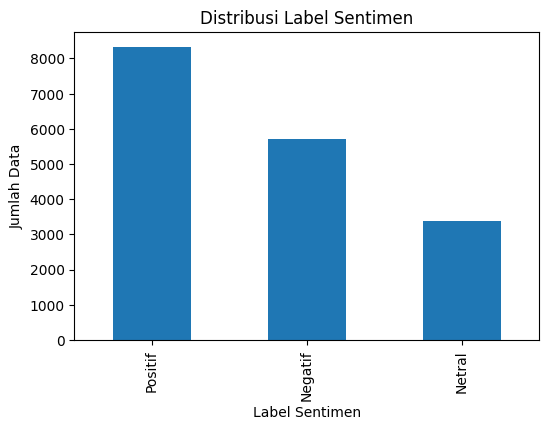

In [ ]:
plt.figure(figsize=(6,4))
df_final["sentiment"].value_counts().plot(kind="bar")
plt.title("Distribusi Label Sentimen")
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Data")
plt.show()

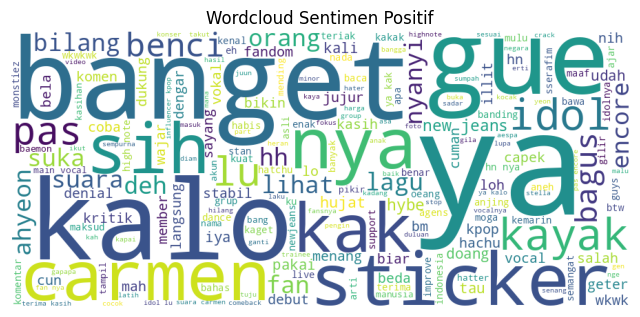

In [ ]:
positive_text = " ".join(
    df_final[
        df_final["sentiment"]=="Positif"
    ]["stemmed2"])

positive_wc = WordCloud(
    width=900,
    height=400,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(8,4))
plt.imshow(positive_wc)
plt.axis("off")
plt.title("Wordcloud Sentimen Positif")
plt.show()

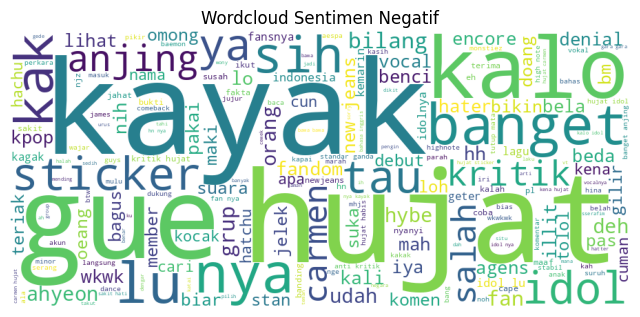

In [ ]:
negative_text = " ".join(
    df_final[
        df_final["sentiment"]=="Negatif"
    ]["stemmed2"])

positive_wc = WordCloud(
    width=900,
    height=400,
    background_color="white"
).generate(negative_text)

plt.figure(figsize=(8,4))
plt.imshow(positive_wc)
plt.axis("off")
plt.title("Wordcloud Sentimen Negatif")
plt.show()

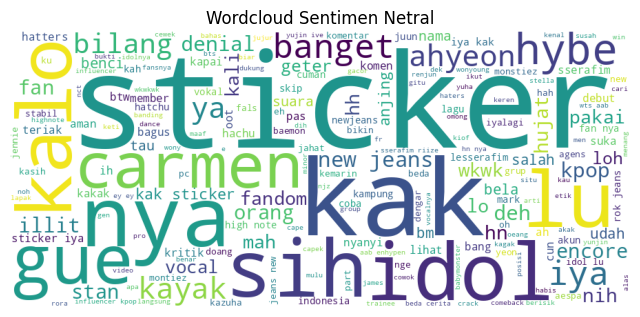

In [ ]:
neutral_text = " ".join(
    df_final[
        df_final["sentiment"]=="Netral"
    ]["stemmed2"])

positive_wc = WordCloud(
    width=900,
    height=400,
    background_color="white"
).generate(neutral_text)

plt.figure(figsize=(8,4))
plt.imshow(positive_wc)
plt.axis("off")
plt.title("Wordcloud Sentimen Netral")
plt.show()

In [ ]:
df_sentiment = df_final[[
    "created_at",
    "username",
    "clean_text",
    "stemmed2",
    "token",
    "sentiment_score",
    "sentiment"
]].copy()

df_sentiment.head()

,created_at,username,clean_text,stemmed2,token,sentiment_score,sentiment
0,2026-07-03T05:52:48.000Z,zgemey,the real teriak,the real teriak,"[the, real, teriak]",0,Netral
1,2026-07-03T06:54:49.000Z,sleeppyy374,deniall abisss komennya,deniall habis komennya,"[deniall, habis, komennya]",3,Positif
2,2026-07-03T08:44:15.000Z,matchaoaas,Sticker gua gabisa bayangin kalo AHYEON yang d...,sticker gue bayang kalo ahyeon posisi hujat ha...,"[sticker, gue, bayang, kalo, ahyeon, posisi, h...",0,Netral
3,2026-07-03T09:06:18.000Z,naevat3rs,Sticker anti kritik bgt,sticker anti kritik banget,"[sticker, anti, kritik, banget]",-6,Negatif
4,2026-07-03T09:32:19.000Z,blueberrygirl324,Sticker mungkin jadwal nya lagi padat jadi ga ...,sticker jadwal nya padat stabil capek grogi,"[sticker, jadwal, nya, padat, stabil, capek, g...",3,Positif


In [ ]:
df_sentiment.to_csv(
    "/content/drive/MyDrive/SKRIPSI/T_PT8/data_sentiment8.csv",
    index=False
)

# **Mapping**

https://github.com/rahmatttt/Indonesian-Hate-Speech-Multilabel-Text-Classification

In [ ]:
import pandas as pd

df_map = df_sentiment[[
    "created_at",
    "username",
    "clean_text",
    "stemmed2",
    "token",
    "sentiment_score",
    "sentiment"
]].copy()
df_hs = pd.read_csv(
    "/content/drive/MyDrive/SKRIPSI/hs_dataset.csv",
    sep=None,
    engine="python"
)
df_hs.head()

,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatia...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0,0,0,0,0,0,0,0,0,0,0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0,0,0,0,0,0,0,0,0,0,0,0
4,USER USER Kaum cebong kapir udah keliatan dong...,1,1,0,1,1,0,0,0,0,0,1,0


In [ ]:
def map_label(row):
    # Hate Speech (SARA)
    if (row["HS_Group"] == 1 or
        row["HS_Religion"] == 1 or
        row["HS_Race"] == 1 or
        row["HS_Gender"] == 1):
        return "hate_speech"

    # Flaming & Harassment
    elif row["Abusive"] == 1:
        return "flaming_harassment"

    # Denigration
    elif row["HS_Individual"] == 1:
        return "denigration"

    else:
        return "non_cb"
df_hs["cb_label"] = df_hs.apply(map_label, axis=1)

In [ ]:
hate_df = df_hs[df_hs["cb_label"] == "hate_speech"]
flame_df = df_hs[df_hs["cb_label"] == "flaming_harassment"]
denig_df = df_hs[df_hs["cb_label"] == "denigration"]
df_hs_final = df_hs[[
    "Tweet",
    "cb_label"
]].copy()
df_hs_final

,Tweet,cb_label
0,- disaat semua cowok berusaha melacak perhatia...,flaming_harassment
1,RT USER: USER siapa yang telat ngasih tau elu?...,flaming_harassment
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",non_cb
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,non_cb
4,USER USER Kaum cebong kapir udah keliatan dong...,hate_speech
...,...,...
18391,Negeri para bencong... Fuck You Malaysia..fuck...,hate_speech
18392,There is no apologize. So there is no peace. #...,non_cb
18393,Your statement is a declaration of war for ind...,non_cb
18394,"Seriously, you are a total joke Malaysia #Sham...",non_cb


In [ ]:
from collections import Counter

def get_top_words(df, col="Tweet", n=150):
    text = " ".join(df[col].astype(str)).lower()
    words = text.split()
    counter = Counter(words)
    return [word for word, freq in counter.most_common(n)]

hate_auto = get_top_words(hate_df)
flame_auto = get_top_words(flame_df)
denig_auto = get_top_words(denig_df)

In [ ]:
def clean_keywords(words):
    blacklist = set([
        'user', 'indonesia', 'yang', '#shameonyoumalaysia', 'dari', 'user:',
        'jadi', 'this', 'that', 'sama', 'orang', 'jokowi', 'mereka', 'like',
        'israel', 'allah', 'your', 'ahok', 'malaysia', 'kita', 'bani',
        'just', 'bisa', 'para', 'juga', 'with', 'bukan', '#2019gantipresiden',
        'tidak', 'tapi', 'have', 'rakyat', 'their', 'semua', 'dengan',
        '#malaysiamiskinbudaya', 'kalo', 'untuk', 'dasar', 'kalian', 'kaum',
        'negara', 'udah', 'hanya', 'buat', 'people', "don't", 'lagi', 'anda',
        'budha', 'cuma', 'sudah', 'partai', 'banyak', 'masih', 'will', 'from',
        'harus', 'akan',  'know', 'what', 'presiden', 'pada', 'kalau', 'adalah',
        'pasti', 'karena', '#prabowogila', 'said', 'because', 'still', 'will',
        'bikin', 'baru', 'cuma', 'jangan', 'dont', 'bisa', 'when', 'banget',
        'have', 'juga', "don't", 'they', 'know', 'lagi', '&amp;', 'masih',
        'saya', 'punya', 'banyak', 'satu', 'sekarang', 'oleh', 'your', 'udah',
        'adalah', 'anies-sandi', 'people', 'like', 'hanya', 'just', 'saat',
        'buat', 'saracen', 'bikin', 'atau', 'memang', 'asing', 'makin', 'malah',
        'jokowi.', 'this', 'bilang', 'pilih', 'baik', 'kami', 'pasti', 'kasus',
        'asma', 'ganti', 'harus'
    ])

    return [
        w for w in words
        if len(w) > 3
        and w not in blacklist
    ]

hate_auto = clean_keywords(hate_auto)
flame_auto = clean_keywords(flame_auto)
denig_auto = clean_keywords(denig_auto)

print("Hate_keywords_Auto: ", hate_auto)
print("Flame_keywords_Auto: ", flame_auto)
print("Denig_keywords_Auto: ", denig_auto)

Hate_keywords_Auto:  ['islam', 'cina', 'cebong', 'agama', 'fuck', 'komunis', 'kafir', 'rezim', 'bubarkan', 'antek', 'muslim', 'usir', 'anti', 'bangsat', 'penista', 'kampret', 'banci', 'babi', 'yahudi']
Flame_keywords_Auto:  ['fuck', 'bangsat', 'anjing', 'kontol', 'cebong', 'about', 'kampungan', 'goblok', 'emang', 'babi', 'berengsek', 'fucking', 'anjir', 'bullshit', 'even', "it's", 'kamu', 'kampret', 'bacot', 'pake', 'ngentot', 'anak', 'memek', 'shit', 'suka']
Denig_keywords_Auto:  ['prabowo', 'lengserkan', 'rezim', 'anies', 'gubernur', 'mundur', '#2019gantipresiden;', 'lebih', 'sandi', 'saja', 'jika', '2019', 'liar', 'dulu', 'korupsi', 'salah', 'turunkan', 'diktator', 'anti', 'islam', 'pencitraan', 'munafik']


In [ ]:
hate_speech_keywords = [
"cina","chindo","pribumi","kafir","islam","kristen","yahudi","hindu","budha",
"ras","rasis","suku","agama","etnis","arab","india","china","melayu","papua",
"hitam","kulit hitam","negro","minoritas","mayoritas",
"dasar cina","dasar kafir","anjing kafir","cina bangsat","ras rendah",
"ras jelek","etnis jelek","suku primitif","orang timur","orang barat",
"fanatik agama","agama sesat","agama bodoh","kaum ini","kaum itu",
"kaum rendahan","orang kampung","orang desa","orang kota sombong",
"keturunan","keturunan jelek","darah kotor","bukan asli",
"imigran","pendatang","asing","orang luar",
"budak","kolonial","penjajah","terbelakang","primitif",
"tidak beradab","tidak punya budaya","budaya rendah",
"agama kalian","orang kalian","kelompok kalian",
"mereka itu","golongan itu","jenis orang itu",
"dasar minoritas","dasar mayoritas sok", "indo", "indonesia", "pribumi", "lokal",
"wna", "ras", "negara"
]

flaming_keywords = [
"anjing","bangsat","kontol","memek","goblok","tolol","idiot","bego",
"sinting","kampret","bacot","tai","anjir","ngentot","brengsek",
"sialan","kurang ajar","bajingan","keparat","setan","iblis",
"tolol banget","goblok banget","bodoh banget","idiot banget",
"lu goblok","lu tolol","lu bego","lu anjing","lu bangsat",
"otak kosong","ga punya otak","otak udang","otak kecil",
"mampus","mati aja","bunuh diri","pergi sana","lenyap aja",
"brengsek lu","kampret lu","bacot lu","tai lu",
"ga guna","sampah","manusia sampah","manusia gagal",
"jelek banget","parah banget","hancur banget",
"ga jelas lu","ga penting","ga ada guna",
"cupu","pecundang","loser","payah","lemah",
"bikin muak","menyebalkan","nyebelin","najis",
"jijik","memuakkan","sakit jiwa","stress",
"gila lu","gila banget","ngaco","halu",
"norak banget","alay banget","kampungan",
"berisik","ribet","rese","nyusahin",
"ganggu banget","parasit","benalu",
"tolol lu","idiot lu","anjing banget",
"bangsat banget","brengsek banget",
"goblok sih","tolol sih","bego sih", "jembut", "babi",
"kontol", "panteq", "pantek", "dongok", "najis", "perek", "busuk", "gila",
"sial", "hujat", "ngehujat", "maki", "ngatain", "iri", "dengki", "nyinyir",
"senggol", "serang", "nyerang", "benci banget", "koar", "bacotin",
"bacotin terus", "julid", "julid banget", "songong", "sok tau", "sok keras",
"cibir", "ngegas", "fales", "sumbang", "teriak", "teriak doang", "kenceng doang",
"ga enak", "gaenak"
]

denigration_keywords = [
"jelek","buruk","ga becus","tidak berguna","memalukan",
"rendahan","ga jelas","overrated","lebay","norak","alay",
"kualitas rendah","jelek banget","parah","hancur",
"gagal","gagal total","tidak layak","tidak pantas",
"tidak kompeten","tidak profesional",
"biasa aja","b aja","mediocre","standar",
"mengecewakan","tidak memuaskan","kurang bagus",
"kurang layak","kurang pintar","kurang cerdas",
"tidak menarik","membosankan","monoton",
"tidak berbakat","tidak punya skill",
"tidak berbobot","kosong","hampa",
"tidak penting","tidak berarti",
"tidak berkelas","murahan",
"tidak berkualitas","receh",
"konten sampah","isi sampah",
"tidak kreatif","tidak inovatif",
"tidak berkembang","stagnan",
"tidak niat","asal jadi",
"tidak serius","tidak fokus",
"kurang usaha","malas","pemalas",
"tidak layak ditonton","tidak layak didengar", "berlagak", "belagu", "memuja",
"geli", "halusinasi", "dukun", "tiruan", "jutek", "males", "biang", "skandal",
"ngeri", "plagiarisme", "duplikat", "hina", "racun", "benci", "haters",
"fomo", "bully", "anti kritik", "denial", "standar ganda", "ga mutu",
"jelek suara",  "pay to win", "dipaksa debut", "dipaksa", "overhype",
"dipuji berlebihan"
]

In [ ]:
hate_speech_keywords = list(set(hate_speech_keywords + hate_auto))
flaming_keywords = list(set(flaming_keywords + flame_auto))
denigration_keywords = list(set(denigration_keywords + denig_auto))

In [ ]:
print(len(hate_speech_keywords))
print(len(flaming_keywords))
print(len(denigration_keywords))

86
139
112


In [ ]:
df_candidate = df_map[
    df_map["sentiment"].isin(["Negatif"])
].copy()

In [ ]:
def classify_cb(text):
    if any(word in text for word in hate_speech_keywords):
        return "hate_speech"
    elif any(word in text for word in flaming_keywords):
        return "flaming_harassment"
    elif any(word in text for word in denigration_keywords):
        return "denigration"

In [ ]:
df_candidate["cb_label"] = df_candidate["stemmed2"].apply(classify_cb)
df_candidate.head()

,created_at,username,clean_text,stemmed2,token,sentiment_score,sentiment,cb_label
3,2026-07-03T09:06:18.000Z,naevat3rs,Sticker anti kritik bgt,sticker anti kritik banget,"[sticker, anti, kritik, banget]",-6,Negatif,hate_speech
6,2026-07-03T10:52:52.000Z,zzrz.o,anti kritik bgt klo ngritik org lain aja gerce...,anti kritik banget kalo ngritik oeang gercep b...,"[anti, kritik, banget, kalo, ngritik, oeang, g...",-5,Negatif,hate_speech
8,2026-07-03T08:36:51.000Z,chaestival43,selama bukan group hybe atau baemon gapapa ama...,group hybe baemon gapapa aman lupa baemon grou...,"[group, hybe, baemon, gapapa, aman, lupa, baem...",-1,Negatif,None
11,2026-07-03T10:52:43.000Z,song.eunso,mereka lagi kecapean emang setiap idol yang la...,cape idol encore kagak capek,"[cape, idol, encore, kagak, capek]",-3,Negatif,None
12,2026-07-03T08:59:39.000Z,zip.echo,heran bgt sama komentar yg nyebut sesama indo ...,heran banget komentar nyebut indonesia hujat g...,"[heran, banget, komentar, nyebut, indonesia, h...",-2,Negatif,hate_speech


In [ ]:
df_candidate["cb_label"].value_counts()

,count
cb_label,
flaming_harassment,2243
denigration,743
hate_speech,476


In [ ]:
df_cb = df_candidate[
    (df_candidate["sentiment"].isin(["Negatif"])) &
    (df_candidate["cb_label"].isin([
        "hate_speech",
        "flaming_harassment",
        "denigration"
    ]))
]

df_cb.head()

,created_at,username,clean_text,stemmed2,token,sentiment_score,sentiment,cb_label
3,2026-07-03T09:06:18.000Z,naevat3rs,Sticker anti kritik bgt,sticker anti kritik banget,"[sticker, anti, kritik, banget]",-6,Negatif,hate_speech
6,2026-07-03T10:52:52.000Z,zzrz.o,anti kritik bgt klo ngritik org lain aja gerce...,anti kritik banget kalo ngritik oeang gercep b...,"[anti, kritik, banget, kalo, ngritik, oeang, g...",-5,Negatif,hate_speech
12,2026-07-03T08:59:39.000Z,zip.echo,heran bgt sama komentar yg nyebut sesama indo ...,heran banget komentar nyebut indonesia hujat g...,"[heran, banget, komentar, nyebut, indonesia, h...",-2,Negatif,hate_speech
22,2026-07-03T15:49:41.000Z,sukabobamatchaa0,standar ganda agensi kalo ahyeon sama wonhe pa...,standar ganda agens kalo ahyeon wonhe hujat ha...,"[standar, ganda, agens, kalo, ahyeon, wonhe, h...",-3,Negatif,flaming_harassment
33,2026-07-03T07:28:34.000Z,ddolie3,jgan denial iaa mungkin carmen kekencengan ket...,denial iya carmen kenceng tinggi highnotenya h...,"[denial, iya, carmen, kenceng, tinggi, highnot...",-7,Negatif,flaming_harassment


In [ ]:
df_cb_final = df_cb[[
    "created_at",
    "username",
    "clean_text",
    "stemmed2",
    "token",
    "sentiment",
    "cb_label"
]].copy()

df_cb_final

,created_at,username,clean_text,stemmed2,token,sentiment,cb_label
3,2026-07-03T09:06:18.000Z,naevat3rs,Sticker anti kritik bgt,sticker anti kritik banget,"[sticker, anti, kritik, banget]",Negatif,hate_speech
6,2026-07-03T10:52:52.000Z,zzrz.o,anti kritik bgt klo ngritik org lain aja gerce...,anti kritik banget kalo ngritik oeang gercep b...,"[anti, kritik, banget, kalo, ngritik, oeang, g...",Negatif,hate_speech
12,2026-07-03T08:59:39.000Z,zip.echo,heran bgt sama komentar yg nyebut sesama indo ...,heran banget komentar nyebut indonesia hujat g...,"[heran, banget, komentar, nyebut, indonesia, h...",Negatif,hate_speech
22,2026-07-03T15:49:41.000Z,sukabobamatchaa0,standar ganda agensi kalo ahyeon sama wonhe pa...,standar ganda agens kalo ahyeon wonhe hujat ha...,"[standar, ganda, agens, kalo, ahyeon, wonhe, h...",Negatif,flaming_harassment
33,2026-07-03T07:28:34.000Z,ddolie3,jgan denial iaa mungkin carmen kekencengan ket...,denial iya carmen kenceng tinggi highnotenya h...,"[denial, iya, carmen, kenceng, tinggi, highnot...",Negatif,flaming_harassment
...,...,...,...,...,...,...,...
17418,NaN,ronni_sinurat,fandom nya munafik parah carmen yang debut di ...,fandom nya munafik parah carmen debut big huja...,"[fandom, nya, munafik, parah, carmen, debut, b...",Negatif,flaming_harassment
17419,NaN,Jungpha1817,Yang bikin males stan idol indo dari agensi nu...,bikin malas stan idol indonesia agens nugu age...,"[bikin, malas, stan, idol, indonesia, agens, n...",Negatif,hate_speech
17422,NaN,Keevapon2509523,Sekarang orang idiot itu mulai adu domba vocal...,orang idiot adu domba vocal skill kim carmen p...,"[orang, idiot, adu, domba, vocal, skill, kim, ...",Negatif,flaming_harassment
17425,NaN,brownnnin,Setuju banget klo mau kritik ya boleh aja ini ...,tuju banget kalo kritik ya hujat begitu gue fa...,"[tuju, banget, kalo, kritik, ya, hujat, begitu...",Negatif,flaming_harassment


In [ ]:
df_cb_final["stemmed2"].isna().sum()

np.int64(0)

In [ ]:
df_cb_final.to_csv("/content/drive/MyDrive/SKRIPSI/T_PT8/data_cyberbullying_final8.csv", index=False)

**Validasi Pakar**

In [ ]:
sample_per_class = 15

df_validation = (
    df_cb_final
    .groupby("cb_label", group_keys=False)
    .apply(lambda x: x.sample(
        n=min(len(x), sample_per_class),
        random_state=42
    ))
    .reset_index(drop=True)
)

/tmp/ipykernel_793/3545512496.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(


In [ ]:
df_validation = df_validation.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

df_validation["label_pakar"] = ""
df_validation["sesuai"] = ""
df_validation["catatan"] = ""

In [ ]:
df_validation.to_excel(
    "/content/drive/MyDrive/SKRIPSI/DATA/validasi_pakar2.xlsx",
    index=False
)

In [ ]:
df_validation = pd.read_excel(
    "/content/drive/MyDrive/SKRIPSI/validasi_pakar2_valid.xlsx"
)

In [ ]:
accuracy = (
    (df_validation["cb_label"] == df_validation["label_pakar"])
    .mean()
    * 100
)

print(f"Tingkat Kesesuaian: {accuracy:.2f}%")

Tingkat Kesesuaian: 77.78%


# **CNN**

In [ ]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Conv1D, Dense, GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.layers import Dropout
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

In [ ]:
# Menyiapkan Data
texts = df_cb_final["stemmed2"]
labels = df_cb_final["cb_label"]

print("Jumlah data :", len(texts))
print(labels.value_counts())

indices = df_cb_final.index

Jumlah data : 3462
cb_label
flaming_harassment    2243
denigration            743
hate_speech            476
Name: count, dtype: int64


In [ ]:
# Label Encoding
le = LabelEncoder()
y = le.fit_transform(labels)

# Melihat hasil encoding label
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))

print(label_mapping)

{'denigration': np.int64(0), 'flaming_harassment': np.int64(1), 'hate_speech': np.int64(2)}


In [ ]:
# Tokenisasi
# Mengambil maksimal 5000 kata paling sering muncul
tokenizer = Tokenizer(
    num_words=5000,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(texts)

# Mengubah teks menjadi urutan angka
X = tokenizer.texts_to_sequences(texts)

# Menyamakan panjang setiap kalimat
X = pad_sequences(
    X,
    maxlen=100,
    padding="post",
    truncating="post"
)

In [ ]:
# Membagi Dataset
X_temp, X_test, y_temp, y_test, idx_temp, idx_test = train_test_split(
    X,
    y,
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y              # pakai stratify agar proporsi setiap kelas tetap sama
)

X_train, X_val, y_train, y_val, idx_train, idx_val = train_test_split(
    X_temp,
    y_temp,
    idx_temp,
    test_size=0.125,
    random_state=42,
    stratify=y_temp
)

print("Train :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

Train : 2422
Validation : 347
Test : 693


In [ ]:
# Class Weight (mengatasi ketidakseimbangan kelas)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(1.5525641025641026), 1: np.float64(0.5145527937114935), 2: np.float64(2.4244244244244246)}


In [ ]:
# Membangun Model CNN
vocab_size = min(
    5000,
    len(tokenizer.word_index) + 1
)

model = Sequential([
    Input(shape=(100,)),      # Input
    Embedding(
        input_dim=vocab_size,
        output_dim=64
    ),                        # Embedding Layer
    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu"
    ),                        # Convolution Layer
    GlobalMaxPooling1D(),     # Pooling Layer
    Dropout(0.3),             # Dropout
    Dense(
        units=16,
        activation="relu"
    ),                        # Fully Connected Layer
    Dropout(0.3),
    Dense(
        units=3,
        activation="softmax"
    )                         # Output Layer
])

In [ ]:
# Compile Model
model.compile(
    optimizer=Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ (None, 100, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 98, 32)         │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_8          │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,755 (1.25 MB)

 Trainable params: 326,755 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Early Stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
# Training Model
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.3980 - loss: 1.0968 - val_accuracy: 0.5159 - val_loss: 1.0754
Epoch 2/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5945 - loss: 1.0586 - val_accuracy: 0.7723 - val_loss: 0.9839
Epoch 3/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6846 - loss: 0.9451 - val_accuracy: 0.7954 - val_loss: 0.7884
Epoch 4/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7531 - loss: 0.7766 - val_accuracy: 0.8098 - val_loss: 0.6215
Epoch 5/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8249 - loss: 0.6099 - val_accuracy: 0.8357 - val_loss: 0.5099
Epoch 6/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8865 - loss: 0.4310 - val_accuracy: 0.8818 - val_loss: 0.3735
Epoch 7/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9174 - loss: 0.3276 - val_accuracy: 0.9020 - val_loss: 0.3171
Epoch 8/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9368 - loss: 0.2432 - val_accuracy: 0.9222 - val_loss

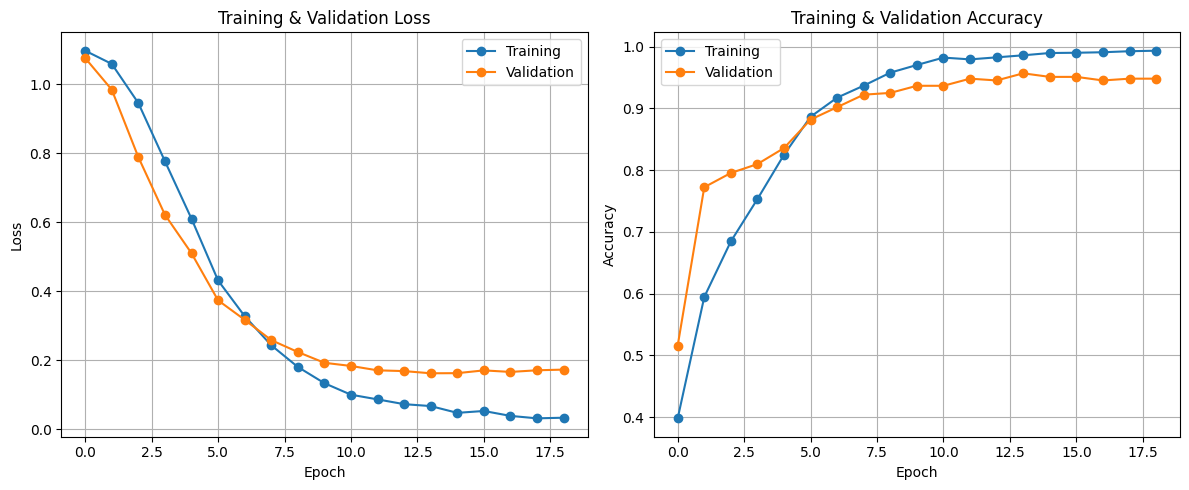

In [ ]:
# Grafik Training CNN
plt.figure(figsize=(12,5))

# Loss
plt.subplot(1,2,1)
plt.plot(
    history.history["loss"],
    marker="o",
    label="Training"
)
plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation"
)
plt.title("Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

# Accuracy
plt.subplot(1,2,2)
plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training"
)
plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation"
)

plt.title("Training & Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Prediksi pada Data Validation dan Test
# Probabilitas prediksi
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

# Mengubah probabilitas menjadi label kelas
y_val_class = np.argmax(
    y_val_pred,
    axis=1
)
y_test_class = np.argmax(
    y_test_pred,
    axis=1
)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


In [ ]:
# Evaluation Validation
print("="*60)
print("Classification Report - Validation")
print("="*60)
print(
    classification_report(
        y_val,
        y_val_class,
        target_names=le.classes_
    )
)

Classification Report - Validation
                    precision    recall  f1-score   support

       denigration       0.95      0.95      0.95        74
flaming_harassment       0.96      0.97      0.97       225
       hate_speech       0.93      0.90      0.91        48

          accuracy                           0.96       347
         macro avg       0.95      0.94      0.94       347
      weighted avg       0.96      0.96      0.96       347



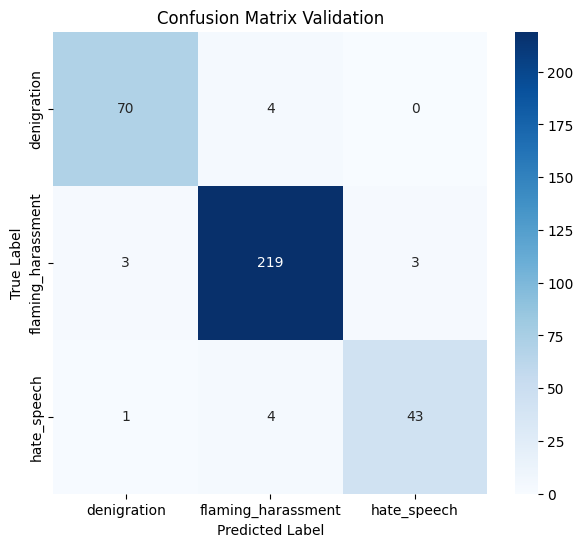

In [ ]:
# Confusion Matrix Validation
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_val,
    y_val_class
)
plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix Validation")

plt.show()

In [ ]:
# Evaluation Test
print("="*60)
print("Classification Report - Test")
print("="*60)
print(
    classification_report(
        y_test,
        y_test_class,
        target_names=le.classes_
    )
)

Classification Report - Test
                    precision    recall  f1-score   support

       denigration       0.87      0.95      0.91       149
flaming_harassment       0.97      0.95      0.96       449
       hate_speech       0.94      0.89      0.92        95

          accuracy                           0.94       693
         macro avg       0.93      0.93      0.93       693
      weighted avg       0.94      0.94      0.94       693



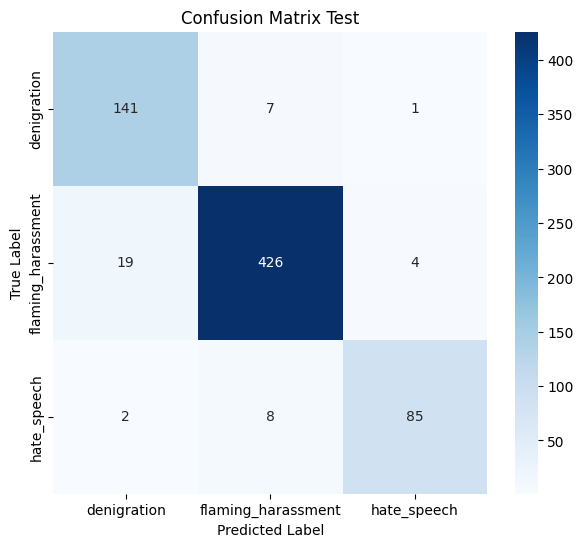

In [ ]:
# Confusion Matrix Test
cm = confusion_matrix(
    y_test,
    y_test_class
)
plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix Test")

plt.show()

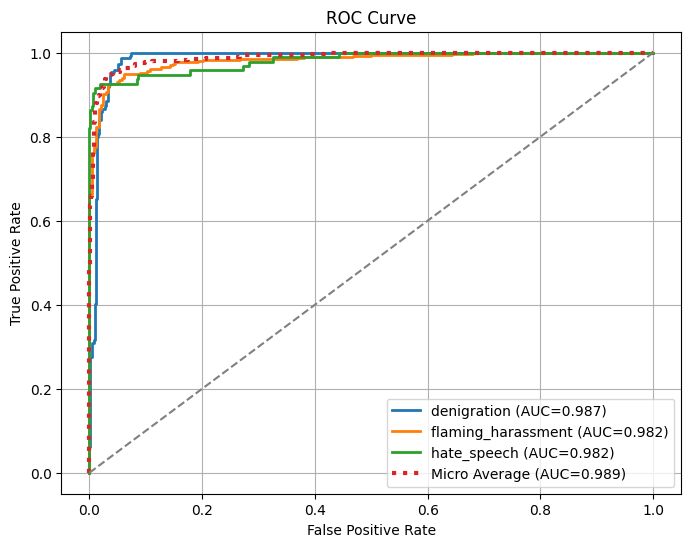

In [ ]:
# ROC Curve Multiclass

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Mengubah label menjadi bentuk biner
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(le.classes_))
)
plt.figure(figsize=(8,6))

# ROC tiap kelas
for i in range(len(le.classes_)):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:,i],
        y_test_pred[:,i]
    )
    roc_auc = auc(fpr,tpr)
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{le.classes_[i]} (AUC={roc_auc:.3f})"
    )

# Micro Average
fpr_micro, tpr_micro, _ = roc_curve(
    y_test_bin.ravel(),
    y_test_pred.ravel()
)
auc_micro = auc(
    fpr_micro,
    tpr_micro
)
plt.plot(
    fpr_micro,
    tpr_micro,
    linestyle=":",
    linewidth=3,
    label=f"Micro Average (AUC={auc_micro:.3f})"
)
plt.plot(
    [0,1],
    [0,1],
    "--",
    color="gray"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# Evaluasi Akhir Model
loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)
print("="*45)
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Loss     : {loss:.4f}")
print("="*45)

Test Accuracy : 0.9408
Test Loss     : 0.1997


In [ ]:
model.save("/content/drive/MyDrive/SKRIPSI/T_PT7/model_cnn7.keras")

In [ ]:
import pickle

with open("/content/drive/MyDrive/SKRIPSI/T_PT7/tokenizer7.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

In [ ]:
with open("/content/drive/MyDrive/SKRIPSI/T_PT7/label_encoder7.pkl", "wb") as f:
    pickle.dump(le, f)

# **MAPPING PASSAL**

1. **Hate Speech** → UU ITE Pasal 28 ayat (2)
“Setiap orang dengan sengaja dan tanpa hak menyebarkan informasi yang ditujukan untuk menimbulkan rasa kebencian atau permusuhan individu dan/atau kelompok masyarakat tertentu berdasarkan atas suku, agama, ras, dan antar golongan (SARA).”

2. **Flaming / Harassment**
* Pasal 315 KUHP
“Tiap-tiap penghinaan ringan yang dilakukan dengan sengaja terhadap seseorang, baik di muka umum maupun di hadapan orang tersebut sendiri, dihukum...”
* Pasal 29 UU ITE
“Setiap orang dengan sengaja dan tanpa hak mengirimkan informasi elektronik yang berisi ancaman kekerasan atau menakut-nakuti yang ditujukan secara pribadi.”

3. **Denigration**
* Pasal 310 KUHP
“Barang siapa sengaja menyerang kehormatan atau nama baik seseorang dengan menuduhkan sesuatu hal supaya diketahui umum...”
* Pasal 311 KUHP
“Jika yang melakukan pencemaran tidak dapat membuktikan kebenaran tuduhannya, maka dianggap sebagai fitnah.”
* Pasal 27 ayat (3) UU ITE
“Setiap orang dengan sengaja dan tanpa hak mendistribusikan informasi elektronik yang memiliki muatan penghinaan dan/atau pencemaran nama baik.”

In [ ]:
# Mengubah hasil prediksi CNN menjadi nama label
# Label numerik -> label asli
y_pred_labels = le.inverse_transform(y_test_class)

In [ ]:
def map_to_law(label):
    if label == "hate_speech":
        return {
            "pasal": ["UU ITE Pasal 28 ayat (2)"],
            "bunyi": [
                "Setiap orang dengan sengaja dan tanpa hak menyebarkan informasi yang menimbulkan kebencian berdasarkan SARA."
            ]
        }

    elif label == "flaming_harassment":
        return {
            "pasal": [
                "KUHP Pasal 315",
                "UU ITE Pasal 29"
            ],
            "bunyi": [
                "Penghinaan ringan atau makian terhadap seseorang.",
                "Larangan pengiriman ancaman kekerasan secara elektronik."
            ]
        }

    elif label == "denigration":
        return {
            "pasal": [
                "KUHP Pasal 310",
                "KUHP Pasal 311",
                "UU ITE Pasal 27 ayat (3)"
            ],
            "bunyi": [
                "Pencemaran nama baik.",
                "Fitnah jika tidak dapat dibuktikan.",
                "Distribusi konten penghinaan elektronik."
            ]
        }

    else:
        return {
            "pasal": ["Tidak diketahui"],
            "bunyi": ["-"]
        }

In [ ]:
# Membuat DataFrame Hasil Prediksi
df_result = df_cb_final.loc[idx_test].copy()
df_result = df_result.reset_index(drop=True)
df_result["predicted_label"] = y_pred_labels

In [ ]:
# Menambahkan Informasi Pasal
df_result["pasal"] = df_result["predicted_label"].apply(
    lambda x: map_to_law(x)["pasal"]
)

df_result["isi_pasal"] = df_result["predicted_label"].apply(
    lambda x: map_to_law(x)["bunyi"]
)

In [ ]:
# Menampilkan Hasil Mapping Pasal
df_result.head(20)

,created_at,username,clean_text,stemmed2,token,sentiment,cb_label,predicted_label,pasal,isi_pasal
0,2026-07-03T12:51:23.000Z,tssedancaa,salah lapak kak jangan kayak gitu nanti takut ...,salah lapak kak kayak takut ahyeon nya hujat,"[salah, lapak, kak, kayak, takut, ahyeon, nya,...",Negatif,flaming_harassment,flaming_harassment,"[KUHP Pasal 315, UU ITE Pasal 29]",[Penghinaan ringan atau makian terhadap seseor...
1,2026-07-04T16:53:50.000Z,bonjouranxiety,Sticker ANJIR,sticker anjing,"[sticker, anjing]",Negatif,flaming_harassment,flaming_harassment,"[KUHP Pasal 315, UU ITE Pasal 29]",[Penghinaan ringan atau makian terhadap seseor...
2,2026-07-04T09:37:11.000Z,gw_gen_z,lu lebih berisik si kritik tapi menjatuhkan,lu berisik sih kritik jatuh,"[lu, berisik, sih, kritik, jatuh]",Negatif,flaming_harassment,flaming_harassment,"[KUHP Pasal 315, UU ITE Pasal 29]",[Penghinaan ringan atau makian terhadap seseor...
3,2026-07-04T05:00:44.000Z,kai52776,sm stan emang toxic suka nyenggol hybe stan sa...,stan racun suka nyenggol hybe stan jyp stan gi...,"[stan, racun, suka, nyenggol, hybe, stan, jyp,...",Negatif,flaming_harassment,flaming_harassment,"[KUHP Pasal 315, UU ITE Pasal 29]",[Penghinaan ringan atau makian terhadap seseor...
4,2026-07-03T12:26:31.000Z,maulidanuraini79,Sticker oouh jadi kalo grup yang di stan harus...,sticker oouh kalo grup stan hujat ya kak en core,"[sticker, oouh, kalo, grup, stan, hujat, ya, k...",Negatif,flaming_harassment,flaming_harassment,"[KUHP Pasal 315, UU ITE Pasal 29]",[Penghinaan ringan atau makian terhadap seseor...
5,2026-07-03T23:07:42.000Z,nazwa.waaaaaa,Apalagi di lapak hh smaa bm mereka hujat nya c...,lapak hh bm hujat nya carmen doang,"[lapak, hh, bm, hujat, nya, carmen, doang]",Negatif,flaming_harassment,flaming_harassment,"[KUHP Pasal 315, UU ITE Pasal 29]",[Penghinaan ringan atau makian terhadap seseor...
6,2026-07-03T23:26:35.000Z,ptryyy_57,liat akunnya kak akun haters folowers nya kaya...,lihat akun kak akun haters folowers nya kayak ...,"[lihat, akun, kak, akun, haters, folowers, nya...",Negatif,denigration,denigration,"[KUHP Pasal 310, KUHP Pasal 311, UU ITE Pasal ...","[Pencemaran nama baik., Fitnah jika tidak dapa..."
7,2026-07-04T12:59:16.000Z,martinedjabrik,serem banget banyak anti kritik,seram banget anti kritik,"[seram, banget, anti, kritik]",Negatif,hate_speech,hate_speech,[UU ITE Pasal 28 ayat (2)],[Setiap orang dengan sengaja dan tanpa hak men...
8,Tue May 27 13:03:02 +0000 2025,sengatrans,Ini yang paling parah tapi so called influence...,parah sok called influencer kpop tiktok kasih ...,"[parah, sok, called, influencer, kpop, tiktok,...",Negatif,denigration,denigration,"[KUHP Pasal 310, KUHP Pasal 311, UU ITE Pasal ...","[Pencemaran nama baik., Fitnah jika tidak dapa..."
9,NaN,acesabethename,Udah gaada lagi bahan untuk menyela kak Jd waj...,bahan sela kak wajar cari bahan hujat gilir id...,"[bahan, sela, kak, wajar, cari, bahan, hujat, ...",Negatif,flaming_harassment,flaming_harassment,"[KUHP Pasal 315, UU ITE Pasal 29]",[Penghinaan ringan atau makian terhadap seseor...
